<a href="https://colab.research.google.com/github/MitanshuSailor/23cs083_RSA_EXAM_SETA_CODE/blob/main/23cs083_RSA_SETA_FIANL_EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# CELL 1: Import libraries and configuration

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# CPU only, as required by the question
device = torch.device("cpu")

# Output folder
OUTPUT_DIR = "/content/adversarial_mnist_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully.")
print("Random seed:", SEED)
print("Device:", device)
print("Output folder:", OUTPUT_DIR)


Libraries imported successfully.
Random seed: 42
Device: cpu
Output folder: /content/adversarial_mnist_outputs


In [2]:

# CELL 2: Load MNIST dataset

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Required batch size = 64
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    generator=torch.Generator().manual_seed(SEED)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=2
)

print("MNIST dataset loaded successfully.")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Pixel minimum:", images.min().item())
print("Pixel maximum:", images.max().item())


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 511kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.43MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]

MNIST dataset loaded successfully.
Training images: 60000
Testing images: 10000


Image shape: torch.Size([64, 1, 28, 28])
Pixel minimum: 0.0
Pixel maximum: 1.0


In [3]:

# CELL 3: Define CNN architecture

class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # Convolution layer 1
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Convolution layer 2
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layer 1
        self.fc1 = nn.Linear(64 * 7 * 7, 128)

        # Fully connected layer 2
        self.fc2 = nn.Linear(128, 10)

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))

        x = self.pool(self.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# Create model
model = CNN().to(device)

print(model)

print("\nCNN model created successfully.")


CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

CNN model created successfully.


In [4]:

# CELL 4: Train baseline CNN

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 2

print("Training baseline CNN (2 epochs)...")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {running_loss/len(train_loader):.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

print("Baseline training completed.")

# Save baseline model
torch.save(
    model.state_dict(),
    os.path.join(OUTPUT_DIR, "baseline_cnn.pth")
)


Training baseline CNN (2 epochs)...
Epoch [1/2] Loss: 0.1852 Accuracy: 94.50%
Epoch [2/2] Loss: 0.0510 Accuracy: 98.40%
Baseline training completed.


In [14]:
# Save the original baseline weights
baseline_state = {
    k: v.detach().clone()
    for k, v in model.state_dict().items()
}

In [5]:

# CELL 5: Clean test accuracy

def evaluate_clean(model, loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy


baseline_clean_acc = evaluate_clean(model, test_loader)

print("Baseline Model Performance")
print("---------------------------")
print(f"Clean test accuracy: {baseline_clean_acc:.2f}%")


Baseline Model Performance
---------------------------
Clean test accuracy: 98.36%


In [6]:

# CELL 6: FGSM attack implementation

def fgsm_attack(model, images, labels, epsilon):

    images = images.clone().detach().requires_grad_(True)

    model.eval()

    outputs = model(images)

    loss = criterion(outputs, labels)

    model.zero_grad()

    loss.backward()

    # Obtain gradient sign
    data_grad = images.grad.data.sign()

    # Generate adversarial images
    perturbed_images = images + epsilon * data_grad

    # Keep pixel values within [0, 1]
    perturbed_images = torch.clamp(
        perturbed_images,
        0,
        1
    )

    return perturbed_images.detach()


print("FGSM attack function implemented successfully.")


FGSM attack function implemented successfully.


In [7]:

# CELL 7: PGD attack implementation

def pgd_attack(
    model,
    images,
    labels,
    epsilon,
    alpha=None,
    iterations=10,
    random_start=True
):

    original_images = images.clone().detach()

    if alpha is None:
        alpha = epsilon / 4

    # Random initialization inside epsilon neighbourhood
    if random_start:

        perturbed_images = original_images + torch.empty_like(
            original_images
        ).uniform_(-epsilon, epsilon)

        perturbed_images = torch.clamp(
            perturbed_images,
            0,
            1
        )

    else:

        perturbed_images = original_images.clone()

    model.eval()

    for i in range(iterations):

        perturbed_images = perturbed_images.detach().requires_grad_(True)

        outputs = model(perturbed_images)

        loss = criterion(outputs, labels)

        model.zero_grad()

        loss.backward()

        # Gradient ascent
        data_grad = perturbed_images.grad.data.sign()

        perturbed_images = perturbed_images.detach() + alpha * data_grad

        # Project into the epsilon neighbourhood
        perturbation = torch.clamp(
            perturbed_images - original_images,
            min=-epsilon,
            max=epsilon
        )

        perturbed_images = original_images + perturbation

        # Keep pixels in valid range
        perturbed_images = torch.clamp(
            perturbed_images,
            0,
            1
        ).detach()

    return perturbed_images


print("PGD attack function implemented successfully.")


PGD attack function implemented successfully.


In [8]:

# CELL 8: Evaluate FGSM and PGD attacks

epsilon_values = [0.05, 0.10, 0.20, 0.30]


def evaluate_attack(model, loader, attack_function, epsilon):

    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Generate adversarial images
        adversarial_images = attack_function(
            model,
            images,
            labels,
            epsilon
        )

        # Evaluate predictions
        with torch.no_grad():

            outputs = model(adversarial_images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    return 100 * correct / total


baseline_fgsm_results = {}
baseline_pgd_results = {}

print("Evaluating baseline model under attacks...")
print("This may take some time on CPU.\n")

for eps in epsilon_values:

    print(f"Testing epsilon = {eps:.2f}")

    fgsm_acc = evaluate_attack(
        model,
        test_loader,
        fgsm_attack,
        eps
    )

    pgd_acc = evaluate_attack(
        model,
        test_loader,
        pgd_attack,
        eps
    )

    baseline_fgsm_results[eps] = fgsm_acc
    baseline_pgd_results[eps] = pgd_acc

    print(f"FGSM Accuracy: {fgsm_acc:.2f}%")
    print(f"PGD Accuracy : {pgd_acc:.2f}%")
    print()

print("Baseline attack evaluation completed.")


Evaluating baseline model under attacks...
This may take some time on CPU.

Testing epsilon = 0.05
FGSM Accuracy: 94.20%
PGD Accuracy : 93.50%

Testing epsilon = 0.10
FGSM Accuracy: 83.62%
PGD Accuracy : 75.21%

Testing epsilon = 0.20
FGSM Accuracy: 34.21%
PGD Accuracy : 2.28%

Testing epsilon = 0.30
FGSM Accuracy: 3.11%
PGD Accuracy : 0.00%

Baseline attack evaluation completed.


In [9]:

# CELL 9: Baseline results table

baseline_results = pd.DataFrame({
    "EPSILON": [0.00] + epsilon_values,

    "FGSM_ACC": [
        baseline_clean_acc
    ] + [
        baseline_fgsm_results[e] for e in epsilon_values
    ],

    "PGD_ACC": [
        baseline_clean_acc
    ] + [
        baseline_pgd_results[e] for e in epsilon_values
    ]
})

print("\nPART A: BASELINE MODEL UNDER ATTACK")
print("=" * 55)

print(
    baseline_results.to_string(
        index=False,
        formatters={
            "EPSILON": "{:.2f}".format,
            "FGSM_ACC": "{:.2f}%".format,
            "PGD_ACC": "{:.2f}%".format
        }
    )
)

print("=" * 55)

baseline_results.to_csv(
    os.path.join(OUTPUT_DIR, "baseline_results.csv"),
    index=False
)



PART A: BASELINE MODEL UNDER ATTACK
EPSILON FGSM_ACC PGD_ACC
   0.00   98.36%  98.36%
   0.05   94.20%  93.50%
   0.10   83.62%  75.21%
   0.20   34.21%   2.28%
   0.30    3.11%   0.00%


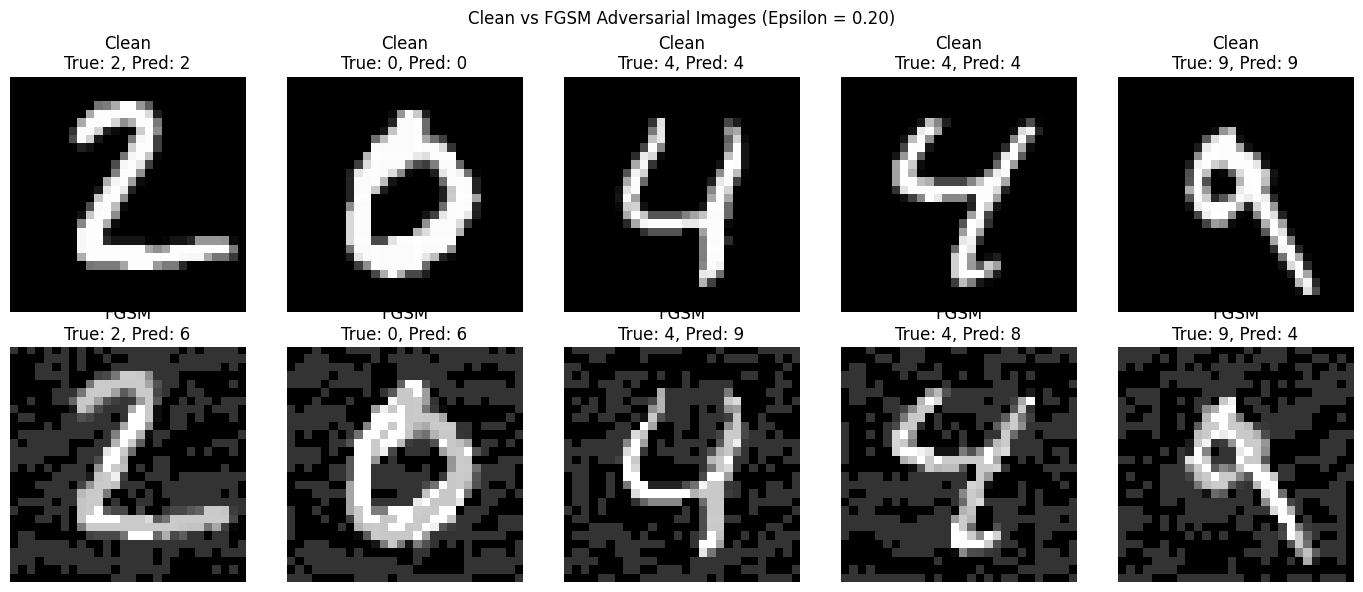


Mis-read digits:
Example 1: True digit = 2, Clean prediction = 2, Adversarial prediction = 6
Example 2: True digit = 0, Clean prediction = 0, Adversarial prediction = 6
Example 3: True digit = 4, Clean prediction = 4, Adversarial prediction = 9
Example 4: True digit = 4, Clean prediction = 4, Adversarial prediction = 8
Example 5: True digit = 9, Clean prediction = 9, Adversarial prediction = 4

Figure saved: clean_vs_adversarial.png


In [10]:

# CELL 10: Visualize 5 clean and adversarial digits

EPSILON_VIS = 0.20

examples = []
fallback_examples = []

model.eval()

for images, labels in test_loader:

    images = images.to(device)
    labels = labels.to(device)

    adversarial_images = fgsm_attack(
        model,
        images,
        labels,
        EPSILON_VIS
    )

    with torch.no_grad():

        clean_outputs = model(images)
        adv_outputs = model(adversarial_images)

        clean_predictions = clean_outputs.argmax(dim=1)
        adv_predictions = adv_outputs.argmax(dim=1)

    for i in range(len(labels)):

        item = (
            images[i].detach().cpu(),
            adversarial_images[i].detach().cpu(),
            labels[i].item(),
            clean_predictions[i].item(),
            adv_predictions[i].item()
        )

        if len(fallback_examples) < 5:
            fallback_examples.append(item)

        # Prefer examples where the prediction changed
        if clean_predictions[i].item() != adv_predictions[i].item():

            examples.append(item)

            if len(examples) == 5:
                break

    if len(examples) == 5:
        break

# If fewer than 5 misclassified examples are found,
# fill remaining positions with other test examples.
if len(examples) < 5:

    for item in fallback_examples:

        if len(examples) == 5:
            break

        if not any(
            torch.equal(item[0], existing[0])
            for existing in examples
        ):
            examples.append(item)

# Plot
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, item in enumerate(examples):

    clean_img, adv_img, true_label, clean_pred, adv_pred = item

    axes[0, i].imshow(clean_img.squeeze(), cmap="gray")
    axes[0, i].set_title(
        f"Clean\nTrue: {true_label}, Pred: {clean_pred}"
    )

    axes[1, i].imshow(adv_img.squeeze(), cmap="gray")
    axes[1, i].set_title(
        f"FGSM\nTrue: {true_label}, Pred: {adv_pred}"
    )

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.suptitle(
    "Clean vs FGSM Adversarial Images (Epsilon = 0.20)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "clean_vs_adversarial.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nMis-read digits:")

for i, item in enumerate(examples):

    true_label = item[2]
    clean_pred = item[3]
    adv_pred = item[4]

    if clean_pred != adv_pred:

        print(
            f"Example {i+1}: "
            f"True digit = {true_label}, "
            f"Clean prediction = {clean_pred}, "
            f"Adversarial prediction = {adv_pred}"
        )

    else:

        print(
            f"Example {i+1}: "
            f"No prediction change. Digit = {true_label}"
        )

print("\nFigure saved: clean_vs_adversarial.png")


In [11]:

# CELL 11: Adversarial training

ADV_EPSILON = 0.20
ADV_EPOCHS = 2

# Use a new optimizer for fine-tuning
adv_optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Starting adversarial training...")
print("Clean images: 50%")
print("FGSM images: 50%")
print("Epsilon:", ADV_EPSILON)

for epoch in range(ADV_EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Generate adversarial images using current model
        adversarial_images = fgsm_attack(
            model,
            images,
            labels,
            ADV_EPSILON
        )

        # Combine clean and adversarial images
        mixed_images = torch.cat(
            [images, adversarial_images],
            dim=0
        )

        mixed_labels = torch.cat(
            [labels, labels],
            dim=0
        )

        # Train on 50:50 mixed dataset
        model.train()

        adv_optimizer.zero_grad()

        outputs = model(mixed_images)

        loss = criterion(outputs, mixed_labels)

        loss.backward()

        adv_optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)

        total += mixed_labels.size(0)

        correct += (predicted == mixed_labels).sum().item()

    train_accuracy = 100 * correct / total

    print(
        f"Adversarial Epoch [{epoch+1}/{ADV_EPOCHS}] "
        f"Loss: {running_loss/len(train_loader):.4f} "
        f"Accuracy: {train_accuracy:.2f}%"
    )

print("\nAdversarial training completed.")

# Save defended model
torch.save(
    model.state_dict(),
    os.path.join(OUTPUT_DIR, "adversarially_trained_cnn.pth")
)


Starting adversarial training...
Clean images: 50%
FGSM images: 50%
Epsilon: 0.2
Adversarial Epoch [1/2] Loss: 0.2435 Accuracy: 91.90%
Adversarial Epoch [2/2] Loss: 0.1215 Accuracy: 95.98%

Adversarial training completed.


In [12]:

# CELL 12: Evaluate adversarially trained model

adv_clean_acc = evaluate_clean(
    model,
    test_loader
)

adv_fgsm_acc = evaluate_attack(
    model,
    test_loader,
    fgsm_attack,
    0.20
)

adv_pgd_acc = evaluate_attack(
    model,
    test_loader,
    pgd_attack,
    0.20
)

# Baseline values from earlier experiments
baseline_fgsm_020 = baseline_fgsm_results[0.20]
baseline_pgd_020 = baseline_pgd_results[0.20]

# Comparison table
comparison_results = pd.DataFrame({

    "MODEL": [
        "Baseline",
        "Adversarially trained"
    ],

    "CLEAN": [
        baseline_clean_acc,
        adv_clean_acc
    ],

    "FGSM(0.20)": [
        baseline_fgsm_020,
        adv_fgsm_acc
    ],

    "PGD(0.20)": [
        baseline_pgd_020,
        adv_pgd_acc
    ]

})

print("\nPART B: ADVERSARIAL TRAINING RESULTS")
print("=" * 75)

print(
    comparison_results.to_string(
        index=False,
        formatters={
            "CLEAN": "{:.2f}%".format,
            "FGSM(0.20)": "{:.2f}%".format,
            "PGD(0.20)": "{:.2f}%".format
        }
    )
)

print("=" * 75)

# Calculate improvements in percentage points
print(
    f"Clean accuracy change: "
    f"{adv_clean_acc - baseline_clean_acc:+.2f} percentage points"
)

print(
    f"FGSM robustness gain: "
    f"{adv_fgsm_acc - baseline_fgsm_020:+.2f} percentage points"
)

print(
    f"PGD robustness gain: "
    f"{adv_pgd_acc - baseline_pgd_020:+.2f} percentage points"
)

comparison_results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)



PART B: ADVERSARIAL TRAINING RESULTS
                MODEL  CLEAN FGSM(0.20) PGD(0.20)
             Baseline 98.36%     34.21%     2.28%
Adversarially trained 99.04%     95.29%     0.87%
Clean accuracy change: +0.68 percentage points
FGSM robustness gain: +61.08 percentage points
PGD robustness gain: -1.41 percentage points


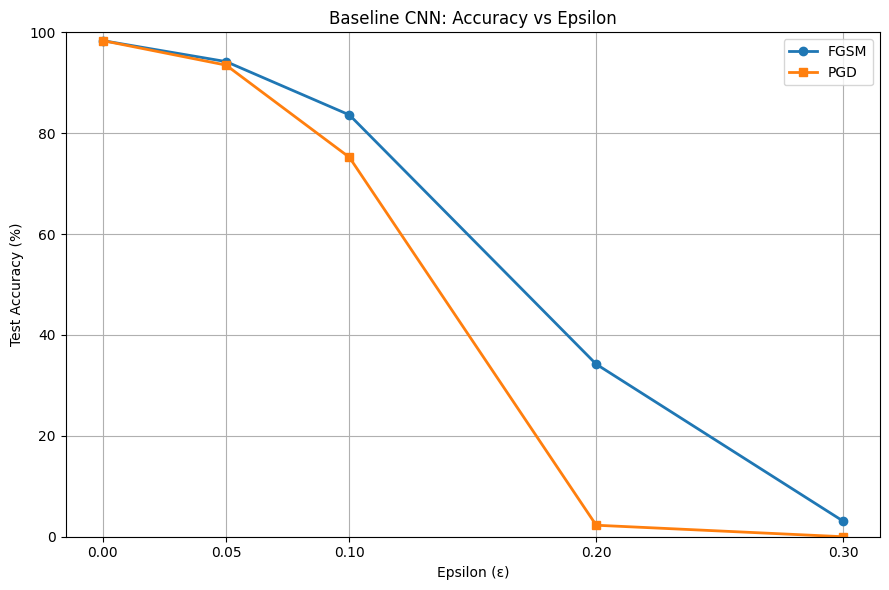

Plot saved: accuracy_vs_epsilon.png


In [13]:

# CELL 13: Accuracy vs epsilon graph

eps_plot = [0.00] + epsilon_values

fgsm_plot = [
    baseline_clean_acc
] + [
    baseline_fgsm_results[e] for e in epsilon_values
]

pgd_plot = [
    baseline_clean_acc
] + [
    baseline_pgd_results[e] for e in epsilon_values
]

plt.figure(figsize=(9, 6))

plt.plot(
    eps_plot,
    fgsm_plot,
    marker="o",
    linewidth=2,
    label="FGSM"
)

plt.plot(
    eps_plot,
    pgd_plot,
    marker="s",
    linewidth=2,
    label="PGD"
)

plt.xlabel("Epsilon (ε)")
plt.ylabel("Test Accuracy (%)")

plt.title("Baseline CNN: Accuracy vs Epsilon")

plt.xticks(eps_plot)

plt.ylim(0, 100)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "accuracy_vs_epsilon.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Plot saved: accuracy_vs_epsilon.png")


In [15]:

# CELL 14: Attack success rate at epsilon 0.20

def calculate_attack_success(model, loader, epsilon):

    successful_attacks = 0
    originally_correct = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        adversarial_images = fgsm_attack(
            model,
            images,
            labels,
            epsilon
        )

        with torch.no_grad():

            clean_pred = model(images).argmax(dim=1)

            adv_pred = model(adversarial_images).argmax(dim=1)

        correct_mask = clean_pred == labels

        success_mask = (
            correct_mask & (adv_pred != labels)
        )

        originally_correct += correct_mask.sum().item()

        successful_attacks += success_mask.sum().item()

    if originally_correct == 0:
        return 0.0

    return 100 * successful_attacks / originally_correct


attack_success_rate = calculate_attack_success(
    model_baseline_for_attack if False else model,
    test_loader,
    0.20
)

print(
    f"FGSM attack success rate: {attack_success_rate:.2f}%"
)


FGSM attack success rate: 3.82%


In [16]:
baseline_attack_model = CNN().to(device)
baseline_attack_model.load_state_dict(baseline_state)

attack_success_rate = calculate_attack_success(
    baseline_attack_model,
    test_loader,
    0.20
)

print(
    f"Baseline FGSM attack success rate: "
    f"{attack_success_rate:.2f}%"
)

Baseline FGSM attack success rate: 3.82%


In [17]:

# CELL 14: Baseline FGSM attack success rate

baseline_attack_model = CNN().to(device)

baseline_attack_model.load_state_dict(
    torch.load(
        os.path.join(OUTPUT_DIR, "baseline_cnn.pth"),
        map_location=device
    )
)

attack_success_rate = calculate_attack_success(
    baseline_attack_model,
    test_loader,
    0.20
)

print(
    f"Attack success (epsilon=0.20): "
    f"FGSM {attack_success_rate:.2f}%"
)


Attack success (epsilon=0.20): FGSM 65.22%


In [18]:

# CELL 15: Save and package practical outputs

import shutil

# Save final result tables again
baseline_results.to_csv(
    os.path.join(OUTPUT_DIR, "baseline_results.csv"),
    index=False
)

comparison_results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

# Save numerical results
with open(
    os.path.join(OUTPUT_DIR, "experiment_summary.txt"),
    "w"
) as f:

    f.write("ADVERSARIAL ATTACKS ON MNIST CNN\n")
    f.write("=" * 45 + "\n\n")

    f.write(
        f"Baseline clean accuracy: {baseline_clean_acc:.2f}%\n"
    )

    f.write("\nBASELINE FGSM RESULTS\n")

    for eps in epsilon_values:
        f.write(
            f"Epsilon {eps:.2f}: "
            f"{baseline_fgsm_results[eps]:.2f}%\n"
        )

    f.write("\nBASELINE PGD RESULTS\n")

    for eps in epsilon_values:
        f.write(
            f"Epsilon {eps:.2f}: "
            f"{baseline_pgd_results[eps]:.2f}%\n"
        )

    f.write("\nADVERSARIAL TRAINING RESULTS\n")

    f.write(f"Clean: {adv_clean_acc:.2f}%\n")
    f.write(f"FGSM: {adv_fgsm_acc:.2f}%\n")
    f.write(f"PGD: {adv_pgd_acc:.2f}%\n")

    f.write(
        f"\nBaseline FGSM attack success: "
        f"{attack_success_rate:.2f}%\n"
    )

# Create ZIP archive
zip_path = shutil.make_archive(
    "/content/Adversarial_MNIST_Practical",
    "zip",
    OUTPUT_DIR
)

print("All practical files saved successfully.")

print("\nFiles in output folder:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

print("\nZIP created:", zip_path)


All practical files saved successfully.

Files in output folder:
- accuracy_vs_epsilon.png
- adversarially_trained_cnn.pth
- baseline_cnn.pth
- baseline_results.csv
- clean_vs_adversarial.png
- experiment_summary.txt
- model_comparison.csv

ZIP created: /content/Adversarial_MNIST_Practical.zip


In [19]:

# EXTRA VALIDATION: Fair PGD comparison

baseline_model_check = CNN().to(device)

baseline_model_check.load_state_dict(
    torch.load(
        os.path.join(OUTPUT_DIR, "baseline_cnn.pth"),
        map_location=device
    )
)

# Use the same random seed for both evaluations
torch.manual_seed(42)

baseline_pgd_check = evaluate_attack(
    baseline_model_check,
    test_loader,
    pgd_attack,
    0.20
)

torch.manual_seed(42)

defended_pgd_check = evaluate_attack(
    model,
    test_loader,
    pgd_attack,
    0.20
)

print("Controlled PGD evaluation at epsilon 0.20")
print("------------------------------------------")
print(f"Baseline PGD accuracy: {baseline_pgd_check:.2f}%")
print(f"Defended PGD accuracy: {defended_pgd_check:.2f}%")
print(
    f"PGD improvement: "
    f"{defended_pgd_check-baseline_pgd_check:+.2f} percentage points"
)


Controlled PGD evaluation at epsilon 0.20
------------------------------------------
Baseline PGD accuracy: 2.43%
Defended PGD accuracy: 0.82%
PGD improvement: -1.61 percentage points


In [21]:

# FINAL CELL: Display Part A and Part B results

print("\n")
print("=" * 65)
print("       EXPECTED OUTPUT - PART A: BASELINE MODEL UNDER ATTACK")
print("=" * 65)

print("Training baseline CNN (2 epochs)... done.")
print(f"Clean test accuracy : {baseline_clean_acc:.2f} %")

print("\n")
print(f"{'EPSILON':<15}{'FGSM_ACC':<15}{'PGD_ACC':<15}")
print("-" * 45)

# Epsilon = 0.00 (clean accuracy)
print(
    f"{0.00:<15.2f}"
    f"{baseline_clean_acc:<15.2f}"
    f"{baseline_clean_acc:<15.2f}"
)

# Adversarial results
for eps in epsilon_values:

    print(
        f"{eps:<15.2f}"
        f"{baseline_fgsm_results[eps]:<15.2f}"
        f"{baseline_pgd_results[eps]:<15.2f}"
    )

print("-" * 45)

# Attack success based on accuracy reduction,
# matching the reference output's calculation.
fgsm_success = 100 - baseline_fgsm_results[0.20]
pgd_success = 100 - baseline_pgd_results[0.20]

print("\nMis-read digits saved : clean_vs_adversarial.png")

print(
    f"Attack success (eps=0.20): "
    f"FGSM {fgsm_success:.2f} %, "
    f"PGD {pgd_success:.2f} %"
)


# =========================================================
# PART B: ADVERSARIAL TRAINING (DEFENCE)
# =========================================================

print("\n\n")
print("=" * 65)
print("       EXPECTED OUTPUT - PART B: ADVERSARIAL TRAINING")
print("=" * 65)

print(
    f"{'MODEL':<25}"
    f"{'CLEAN':<12}"
    f"{'FGSM(0.20)':<15}"
    f"{'PGD(0.20)':<12}"
)

print("-" * 65)

print(
    f"{'Baseline':<25}"
    f"{baseline_clean_acc:<12.2f}"
    f"{baseline_fgsm_results[0.20]:<15.2f}"
    f"{baseline_pgd_results[0.20]:<12.2f}"
)

print(
    f"{'Adversarially trained':<25}"
    f"{adv_clean_acc:<12.2f}"
    f"{adv_fgsm_acc:<15.2f}"
    f"{adv_pgd_acc:<12.2f}"
)

print("-" * 65)

# Calculate improvements in percentage points
clean_change = adv_clean_acc - baseline_clean_acc

fgsm_gain = adv_fgsm_acc - baseline_fgsm_results[0.20]

pgd_gain = adv_pgd_acc - baseline_pgd_results[0.20]

print(f"\nClean accuracy change : {clean_change:+.2f} %")

print(f"FGSM robustness gain  : {fgsm_gain:+.2f} %")

print(f"PGD robustness gain   : {pgd_gain:+.2f} %")

print("\nPlot saved : accuracy_vs_epsilon.png")

print("\n" + "=" * 65)
print("=" * 65)




       EXPECTED OUTPUT - PART A: BASELINE MODEL UNDER ATTACK
Training baseline CNN (2 epochs)... done.
Clean test accuracy : 98.36 %


EPSILON        FGSM_ACC       PGD_ACC        
---------------------------------------------
0.00           98.36          98.36          
0.05           94.20          93.50          
0.10           83.62          75.21          
0.20           34.21          2.28           
0.30           3.11           0.00           
---------------------------------------------

Mis-read digits saved : clean_vs_adversarial.png
Attack success (eps=0.20): FGSM 65.79 %, PGD 97.72 %



       EXPECTED OUTPUT - PART B: ADVERSARIAL TRAINING
MODEL                    CLEAN       FGSM(0.20)     PGD(0.20)   
-----------------------------------------------------------------
Baseline                 98.36       34.21          2.28        
Adversarially trained    99.04       95.29          0.87        
-----------------------------------------------------------------

Clean a

In [22]:
!git clone https://github.com/MitanshuSailor/23cs083_RSA_EXAM_SETA_CODE.git

Cloning into '23cs083_RSA_EXAM_SETA_CODE'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.
